# **Sesión 2:** Calibración de Cámara 📷⚙️

## 0. Preparación

In [1]:
import cv2
print("OpenCV should be 4.8.0.76 Current version:", cv2.__version__)
from typing import List
import numpy as np
import imageio
import cv2
import copy
import glob # Librería necesaria para buscar nombres de paths con patrones concretos, usando *, etc.
import matplotlib.pyplot as plt

OpenCV should be 4.8.0.76 Current version: 4.8.0


## **Apartado A: Calibración de cámara** (derecha e izquierda)

En este apartado se realiza la calibración de dos cámaras de un sistema estereoscópico. Para ello se trabajará con las imágenes de las carpetas ``left`` y ``right``. En primer lugar se trabajará con la carpeta ``left``. Posteriormente, deberá repetir el proceso con las imágenes en la carpeta ``right``. Ambas carpetas contienen imágenes con las que se calibrarán las cámaras. En ellas aparece el patrón de calibración en diferentes posiciones y orientaciones. Estas imágenes serán los datos de entrada.

Los pasos que deberá seguir para calibrar una cámara son:

1. Defina y ejecute el método para cargar imágenes ``load_images()``.
2. Detecte las esquinas de los patrones usando ``cv2.findChessboardCorners()``. Refine las detecciones con ``cv2.cornerSubPix()``.
3. Compruebe que las detecciones son correctas dibujando los resultados con ``cv2.drawChessboardCorners()``.
4. Defina y ejecute el método ``get_chessboard_points(chessboard_shape, dx, dy)`` que proporcione las coordenadas 3D de las esquinas del patrón. El sistema de referencia utilizado deberá estar anclado al propio patrón.
5. Utilice ``cv2.calibrateCamera`` para obtener los parámetros de calibración para la cámara izquierda.

### **Tarea A.1:** Defina y ejecute el método para cargar imágenes ``load_images()``.

In [2]:
def load_images(filenames: List) -> List:
    return [imageio.imread(filename) for filename in filenames]

In [3]:
# TODO Build a list containing the paths of all images from the left camera

imgs_gen_path = '../data/left/*.jpg' # Patrón que cumplen todos los paths de los archivos de imágenes de la carpeta left
imgs_path = sorted(glob.glob(imgs_gen_path))  # Cogemos todos los paths que cumplen ese patrón genérico (usando glob) y los ordenamos (usando sorted)
imgs = load_images(imgs_path)  # Le pasamos a load_images la lista de paths o filenames de las imágenes que queremos cargar

imgs_path

C:\Temp\Win\ipykernel_21776\283608422.py:2: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  return [imageio.imread(filename) for filename in filenames]


['../data/left\\left_000.jpg',
 '../data/left\\left_001.jpg',
 '../data/left\\left_002.jpg',
 '../data/left\\left_003.jpg',
 '../data/left\\left_004.jpg',
 '../data/left\\left_005.jpg',
 '../data/left\\left_006.jpg',
 '../data/left\\left_007.jpg',
 '../data/left\\left_008.jpg',
 '../data/left\\left_009.jpg',
 '../data/left\\left_010.jpg',
 '../data/left\\left_011.jpg',
 '../data/left\\left_012.jpg',
 '../data/left\\left_013.jpg',
 '../data/left\\left_014.jpg',
 '../data/left\\left_015.jpg',
 '../data/left\\left_016.jpg',
 '../data/left\\left_017.jpg',
 '../data/left\\left_018.jpg']

### **Tarea A.2:** Detecte las esquinas de los patrones usando ``cv2.findChessboardCorners()``. Refine las detecciones con ``cv2.cornerSubPix()``.

In [4]:
# Contamos a mano cuantas esquinas de filas y columnas hay en el tablero de chess
pattern_size = (8,6)  # Sigue el formato fila, columna. Indica cuántas esquinas interiores hay que detectar en cada fila y cada columna 

In [5]:
# TODO Find corners with cv2.findChessboardCorners()

# La función findChessboardCorners se encarga de encontrar las esquinas (corners) del tablero de cada una de las imágenes que se le pasen, 
# devuelve una tupla de un booleano que indica si se ha encontrado el patrón completo del tablero o no, y luego un array que muestra las coordenadas de las esquinas detectadas
# El primer parámetro de la función findChessboardCorners debe ser una imagen a color o escala de grises, por eso decidimos pasarla a escala de grises
corners = [cv2.findChessboardCorners(
    cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), pattern_size) # Además de la imagen, es importante pasar como parámetro el número de esquinas interiores a detectar en el tablero
    for img in imgs]  # Todo este proceso lo hacemos para cada imagen de las cargadas, por eso este bucle

In [6]:
len(corners)  # Vemos que tenemos 19 tuplas de resultados, una por cada imagen de la cámara left que hemos usado. En cada tupla tendremos las coordenadas de las corners detectadas

19

In [7]:
# Si accedemos por ejemplo a uno de los arrays resultado, vemos que tiene dimensiones (48,1,2) porque hay 6x8 = 48 esquinas, y cada esquina necesita 2 oordenadas para ser descrita, la coordenada x y la coordenada y
corners[0][1].shape  

(48, 1, 2)

In [8]:
# Hacemos por seguridad una copia de las esquinas detectadas
corners_copy = copy.deepcopy(corners)  

# Este es el criterio de parada que se usará en cornerSubPix, indica cuándo detener la iteración (por precisión alcanzada o por número máximo de iteraciones)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01) # En nuestro caso usaremos de condiciones tanto un máximo de 30 iteraciones, como precisión mínima a obtener de 0.01

# TODO To refine corner detections with cv2.cornerSubPix() you need to input grayscale images. Build a list containing grayscale images.
imgs_gray = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in imgs] # pasamos a grises las imágenes

# La función de cornerSubPix busca corners de manera más precisa ya que utiliza gradientes y consigue de forma iterativa encontrar la localización del corner de forma más exacta que findChessboardCorners
# A la función hay que pasarle como argumentos, la imagen del tablero, las coordenadas iniciales de las esquinas interiores que se habían detectado con findChessboardCorners, 
# el pattern_size de nuevo, el tamaño de una región sin usar en el centro de la ventana (se puede poner (-1, -1) para desactivar esta exclusión), y el criterio de parada del algoritmo
corners_refined = [cv2.cornerSubPix(i, cor[1], pattern_size, (-1, -1), criteria) if cor[0] else [] for i, cor in zip(imgs_gray, corners_copy)]

In [9]:
# A diferencia de findChessboardCorners, la función de cornerSubPix solo nos devuelve el array con las coordenadas encontradas de las esquinas inferiores. 
# Sin booleano de confirmación de que se encontró el patrón.
corners_refined[0].shape


(48, 1, 2)

### **Tarea A.3:** Compruebe que las detecciones son correctas dibujando los resultados con ``cv2.drawChessboardCorners()``

In [10]:
# Hacemos una copia de las imágenes de los tableros, ya que luego vamos a usar drawChessboardCorners para dibujar los corners encontrados en el tablero y se sobreescriben las imágenes
imgs_copy = copy.deepcopy(imgs) 

In [11]:
# TODO Use cv2.drawChessboardCorners() to draw the cornes

for i in range(len(corners_copy)):
    # Solo dibujamos las imágenes que tienen True en ret, es decir, que al buscar sus corners, se ha encontrado correctamente el patrón que se buscaba
    ret = corners_copy[i][0]
    if ret: # Este if es innecesario realmente porque al pasar luego ret como parámetro de drawChessboardCorners, se comprueba automáticamente, pero inicialmente no lo sabíamos y lo hicimos así
        # La función de drawChessboardCorners toma la imagen donde se va a dibujar el patrón de esquinas detectadas, el tamaño del patrón del tablero (esquinas interiores), 
        # las esquinas encontradas (le pasamos las refinadas que habíamos obtenido con cornerSubPix, y el booleano ret que hace que pintemos o no en función de si se encontró el patrón)
        cv2.drawChessboardCorners(imgs_copy[i], pattern_size, corners_refined[i], ret) # La función drawChessboardCorners no devuelve nada, solo modifica la imagen y dibuja sobre ella
        cv2.imshow(f"Img {i} and corners", imgs_copy[i])  # Una vez ya hemos sobreescrito la imagen, la mostramos. Se ve el tablero y las esquinas interiores encontradas sobre él
        cv2.waitKey(0)

cv2.destroyAllWindows()

In [12]:
# Comprobamos que al usar drawChessboardCorners, las imágenes que se le pasan como primer parámetro quedan sobreescritas, por eso convenía hacer previamente una copia de seguridad para no perder las imágenes iniciales
cv2.imshow("Img",imgs_copy[0])
cv2.waitKey(0)
cv2.destroyAllWindows()

In [13]:
import os  # Importamos la librería de os para poder crear los directorios donde almacenaremos nuestras imágenes

# TODO Complete the method, use every argument
def show_image(img: np.array, img_name: str = "Image"):
    cv2.imshow(img_name, img)  # Mostramos la imagen, poniendole el nombre correspondiente a la ventana desplegada
    cv2.waitKey(0)  # Ponemos una tecla para eliminar la ventana y pasar a la siguiente imagen o terminar la visualización
    cv2.destroyAllWindows()

# TODO Complete the method, use every argument
def write_image(output_folder: str, img_name: str, img: np.array):
    img_path = os.path.join(output_folder, img_name)  # Creamos el path donde vamos a guardar la imagen
    os.makedirs(output_folder, exist_ok=True)  # Creamos el directorio necesario para guardar la imagen con el path que queremos. En caso de que ya exista, no hacemos nada
    cv2.imwrite(img_path, img)  # Guardamos la imagen en su correspondiente ubicación


In [14]:
# Guardamos todas las imágenes de los tableros con sus esquinas interiores encontradas y señalizadas
for i in range(len(imgs_copy)):
    write_image("imagenes_esquinas_left_camera_cornerSubPix", f"patron_{i}.jpg", imgs_copy[i])

### **Tarea A.4:** Defina y ejecute el método ``get_chessboard_points(chessboard_shape, dx, dy)``

In [ ]:
# TODO Design the method. It should return a np.array with np.float32 elements
def get_chessboard_points(chessboard_shape, dx, dy):

    cols, rows = chessboard_shape  # Se separan los valores de columnas y filas (número de esquinas interiores en cada dirección)

    grid_xy = np.mgrid[0:cols, 0:rows].T.reshape(-1,2) # Creamos una cuadrícula con las coordenadas 2D del tablero
    # np.mgrid genera una malla de coordenadas (una rejilla regular) con todos los pares (x, y) posibles
    # .T.reshape(-1,2) reorganiza la cuadrícula en una lista de puntos con forma (N, 2), donde N = cols * rows

    objp = np.zeros([grid_xy.shape[0], 3], dtype=np.float32)  # Creamos una matriz de ceros para los puntos 3D, que a continuación rellenaremos

    # dx y dy es el tamaño del espacio que hay entre esquinas en sentido vertical y horizontal
    objp[:,0] = grid_xy[:,0]*dx  # (coordenada X) se rellena multiplicando las posiciones de la cuadrícula por la distancia real entre esquinas en X (dx)
    objp[:,1] = grid_xy[:,1]*dy  # (coordenada Y) se rellena igual, pero con la distancia en Y (dy)

    # Devolvemos los puntos del tablero tal y como son en el mundo real, con su posición teórica exacta. 
    # Nos servirá para comparar esas posiciones con las posiciones encontradas por cornerSubPix y findChessboardCorners
    return objp  

In [16]:
# TODO You need the points for every image, not just one (consider a list comprehension)

# De esta forma obtenemos la ubicación (coordenadas x,y,z) de los pixeles que son esquinas de los tableros. Esta es la ubicación real de las esquinas, que será usada como object points más adelante
dx, dy = 30, 30
chessboard_points = [get_chessboard_points(pattern_size, dx, dy) for _ in corners_refined]


In [17]:
# Comprobamos que la forma de la cuadrícula generada es la correcta
chessboard_points[0]

array([[  0.,   0.,   0.],
       [ 30.,   0.,   0.],
       [ 60.,   0.,   0.],
       [ 90.,   0.,   0.],
       [120.,   0.,   0.],
       [150.,   0.,   0.],
       [180.,   0.,   0.],
       [210.,   0.,   0.],
       [  0.,  30.,   0.],
       [ 30.,  30.,   0.],
       [ 60.,  30.,   0.],
       [ 90.,  30.,   0.],
       [120.,  30.,   0.],
       [150.,  30.,   0.],
       [180.,  30.,   0.],
       [210.,  30.,   0.],
       [  0.,  60.,   0.],
       [ 30.,  60.,   0.],
       [ 60.,  60.,   0.],
       [ 90.,  60.,   0.],
       [120.,  60.,   0.],
       [150.,  60.,   0.],
       [180.,  60.,   0.],
       [210.,  60.,   0.],
       [  0.,  90.,   0.],
       [ 30.,  90.,   0.],
       [ 60.,  90.,   0.],
       [ 90.,  90.,   0.],
       [120.,  90.,   0.],
       [150.,  90.,   0.],
       [180.,  90.,   0.],
       [210.,  90.,   0.],
       [  0., 120.,   0.],
       [ 30., 120.,   0.],
       [ 60., 120.,   0.],
       [ 90., 120.,   0.],
       [120., 120.,   0.],
 

In [18]:
# Además, vemos que las dimensiones de la cuadrícula de cada imagen son (48, 3) ya que hay 6x8 esquinas, y cada esquina está dada por unas coordenadas x,y,z (con la z siempre en cero)
chessboard_points[0].shape

(48, 3)

### **Tarea A.5:** Utilice ``cv2.calibrateCamera()`` para obtener los parámetros de calibración para la cámara izquierda

In [19]:
# Filter data and get only those with adequate detections
valid_corners = [cor[1] for cor in corners if cor[0]]  # Seleccionamos solo los corners encontrados cuando el booleano de findChessboardCorners es True (patrón encontrado con éxito)
# se está cogiendo los corners que se obtuvieron con findChessboardCorners en vez de coger los de cornerSubPix (más precisos) pero el código ya venía así dado en el enunciado

# Convert list to numpy array
valid_corners = np.asarray(valid_corners, dtype=np.float32)

In [20]:
# TODO

img_size = (imgs_gray[0].shape[1], imgs_gray[0].shape[0])  # Extraemos el tamaño de las imágenes: 320 x 240

# La función de calibrateCamera toma como argumentos los chessboard_points, que son los "objectPoints", es decir las coordenadas reales de las esquinas que hemos calculado nosotros usando 
# el grid y la distancia entre esquinas, luego los valid_corners, que son las posiciones de las esquinas que se han encontrado analizando las distintas imágenes usando findChessboardCorners,
# y además se le pasa el tamaño de las imágenes (img_size) y otros 2 argumentos: InputOutputArray (cameraMatrix) y InputOutputArray (distCoeffs) que no usamos 
rms, intrinsics, dist_coeffs, rvecs, tvecs = cv2.calibrateCamera(chessboard_points, valid_corners, img_size, None, None)
# calibrateCamera nos devuelve el error de reproyección (rms), los parámetros intrínsecos, y rvecs y tvecs que nos sirven para hallar los parámetros extrínsecos de la calibración de la cámara

# Obtain extrinsics
extrinsics = list(map(lambda rvec, tvec: np.hstack((cv2.Rodrigues(rvec)[0], tvec)), rvecs, tvecs))  # de esta forma obtenemos los parámetros extrínsecos de la calibración de la cámara

In [21]:
# Print outputs
print("Intrinsics:\n", intrinsics)
print("\nDistortion coefficients:\n", dist_coeffs)
print("\nRoot mean squared reprojection error:\n", rms)
print("\nExtrinsics:\n", extrinsics)

Intrinsics:
 [[417.77315866   0.         156.33829983]
 [  0.         421.35480199 134.32880063]
 [  0.           0.           1.        ]]

Distortion coefficients:
 [[-2.13049815e-01  2.86830664e+00  5.90990527e-03 -3.86453734e-03
  -2.23696363e+01]]

Root mean squared reprojection error:
 0.1846287136881559

Extrinsics:
 [array([[ 7.14810441e-01,  6.18321143e-01, -3.26687920e-01,
        -3.08750936e+01],
       [-1.82439734e-01,  6.15857353e-01,  7.66443387e-01,
        -3.73702013e+01],
       [ 6.75101309e-01, -4.88260878e-01,  5.53027611e-01,
         5.18490853e+02]]), array([[ 7.19016600e-01,  6.02026625e-01, -3.47244973e-01,
        -5.72888930e+01],
       [-1.91372353e-01,  6.51826460e-01,  7.33824835e-01,
        -4.64598332e+01],
       [ 6.68125550e-01, -4.61179151e-01,  5.83885297e-01,
         5.07766905e+02]]), array([[ 7.28774287e-01,  5.83716857e-01, -3.57998142e-01,
        -6.83872714e+01],
       [-2.03244636e-01,  6.83645704e-01,  7.00942344e-01,
        -6.2118

### **Pregunta A.1:** Repita el proceso (carga de imágenes, detección y comprobación de esquinas, etc.) para la cámara derecha.

In [22]:
# TODO Homework
# TODO Build a list containing the paths of all images from the left camera

imgs_gen_path_right = '../data/right/*.jpg' # patrón que cumplen todos los paths de los archivos de imágenes
imgs_path_right = sorted(glob.glob(imgs_gen_path_right))  # cogemos todos los paths que cumplen ese patrón genérico (usando glob) y los ordenamos (usando sorted)
imgs_right = load_images(imgs_path_right)  # le pasamos a load_images la lista de paths o filenames de las imágenes que queremos cargar

imgs_path_right

C:\Temp\Win\ipykernel_21776\283608422.py:2: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  return [imageio.imread(filename) for filename in filenames]


['../data/right\\right_000.jpg',
 '../data/right\\right_001.jpg',
 '../data/right\\right_002.jpg',
 '../data/right\\right_003.jpg',
 '../data/right\\right_004.jpg',
 '../data/right\\right_005.jpg',
 '../data/right\\right_006.jpg',
 '../data/right\\right_007.jpg',
 '../data/right\\right_008.jpg',
 '../data/right\\right_009.jpg',
 '../data/right\\right_010.jpg',
 '../data/right\\right_011.jpg',
 '../data/right\\right_012.jpg',
 '../data/right\\right_013.jpg',
 '../data/right\\right_014.jpg',
 '../data/right\\right_015.jpg',
 '../data/right\\right_016.jpg',
 '../data/right\\right_017.jpg',
 '../data/right\\right_018.jpg']

In [23]:
# Encontramos las esquinas usando findChessboardCorners
corners_right = [cv2.findChessboardCorners(
    cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), pattern_size) 
    for img in imgs_right]  

In [24]:
len(corners_right)  # comprobamos que tenemos 19 resultados, igual que sucedía con la cámara izquierda

19

In [25]:
corners_right[0][1].shape  # las dimensiones son también las mismas, por los mismo motivos que hemos explicado con la cámara izquierda

(48, 1, 2)

In [26]:
# Hacemos por seguridad una copia de las esquinas detectadas
corners_copy_right = copy.deepcopy(corners_right)  

# Este es el criterio de parada que se usará en cornerSubPix, indica cuándo detener la iteración (por precisión alcanzada o por número máximo de iteraciones)
criteria_right = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01) # En nuestro caso usaremos de condiciones tanto un máximo de 30 iteraciones, como precisión mínima a obtener de 0.01

# TODO To refine corner detections with cv2.cornerSubPix() you need to input grayscale images. Build a list containing grayscale images.
imgs_gray_right = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in imgs_right] # pasamos a grises las imágenes

# La función de cornerSubPix busca corners de manera más precisa ya que utiliza gradientes y consigue de forma iterativa encontrar la localización del corner de forma más exacta que findChessboardCorners
# A la función hay que pasarle como argumentos, la imagen del tablero, las coordenadas iniciales de las esquinas interiores que se habían detectado con findChessboardCorners, 
# el pattern_size de nuevo, el tamaño de una región sin usar en el centro de la ventana (se puede poner (-1, -1) para desactivar esta exclusión), y el criterio de parada del algoritmo
corners_refined_right = [cv2.cornerSubPix(i, cor[1], pattern_size, (-1, -1), criteria_right) if cor[0] else [] for i, cor in zip(imgs_gray_right, corners_copy_right)]

In [27]:
# A diferencia de findChessboardCorners, la función de cornerSubPix solo nos devuelve el array con las coordenadas encontradas de las esquinas inferiores. 
# Sin booleano de confirmación de que se encontró el patrón.
corners_refined_right[0].shape

(48, 1, 2)

In [28]:
# Comprobamos que las detecciones de las esquinas son correctas dibujando los resultados
imgs_copy_right = copy.deepcopy(imgs_right) 

for i in range(len(corners_copy_right)):
    # Solo dibujamos las imágenes que tienen True en ret, es decir, que al buscar sus corners, se ha encontrado correctamente el patrón que se buscaba
    ret = corners_copy_right[i][0]
    if ret: # Este if es innecesario realmente porque al pasar luego ret como parámetro de drawChessboardCorners, se comprueba automáticamente, pero inicialmente no lo sabíamos y lo hicimos así
        # La función de drawChessboardCorners toma la imagen donde se va a dibujar el patrón de esquinas detectadas, el tamaño del patrón del tablero (esquinas interiores), 
        # las esquinas encontradas (le pasamos las refinadas que habíamos obtenido con cornerSubPix, y el booleano ret que hace que pintemos o no en función de si se encontró el patrón)
        cv2.drawChessboardCorners(imgs_copy_right[i], pattern_size, corners_refined_right[i], ret) # La función drawChessboardCorners no devuelve nada, solo modifica la imagen y dibuja sobre ella
        cv2.imshow(f"Img {i} and corners", imgs_copy_right[i])  # Una vez ya hemos sobreescrito la imagen, la mostramos. Se ve el tablero y las esquinas interiores encontradas sobre él
        cv2.waitKey(0)

cv2.destroyAllWindows()

In [29]:
# Comprobamos que al usar drawChessboardCorners, las imágenes que se le pasan como primer parámetro quedan sobreescritas, por eso convenía hacer previamente una copia de seguridad para no perder las imágenes iniciales
cv2.imshow("Img",imgs_copy_right[0])
cv2.waitKey(0)
cv2.destroyAllWindows()

In [30]:
# Guardamos todas las imágenes de los tableros con sus esquinas interiores encontradas y señalizadas
for i in range(len(imgs_copy_right)):
    write_image("imagenes_esquinas_right_camera_cornerSubPix", f"patron_{i}.jpg", imgs_copy_right[i])

# Aquí estamos guardando las 19, pero hay 2 de ellas (la número 1 y número 14) que como no se ha encontrado bien su patrón (ret = False), no se ha aplicado la función de drawChessboardCorners sobre ellas

In [31]:
# Comparamos visualmente el resultado de la búsqueda de esquinas con la cámara derecha vs con la cámara izquierda

n = 3

# Cámara izquierda
cv2.imshow("Img pattern with left camera ",imgs_copy[n])
cv2.waitKey(0)
cv2.destroyAllWindows()

# Cámara derecha
cv2.imshow("Img pattern with right camera ",imgs_copy_right[n])
cv2.waitKey(0)
cv2.destroyAllWindows()

In [32]:
# Mostramos 2 imágenes con detección de esquinas, como indica el enunciado:
cv2.imshow(f"Img {n} pattern with right camera ", imgs_copy_right[n])
cv2.waitKey(0)
cv2.destroyAllWindows()

cv2.imshow(f"Img {n+1} pattern with right camera ", imgs_copy_right[n+1])
cv2.waitKey(0)
cv2.destroyAllWindows()

In [33]:
# Ahora definimos la ubicación exacta de las esquinas de los tableros (para la cámara derecha), usando get_chessboard_points
chessboard_points_right = [get_chessboard_points(pattern_size, dx, dy) for _ in corners_refined_right]

# Comprobamos que la forma de la cuadrícula generada es la correcta
chessboard_points_right[0]

array([[  0.,   0.,   0.],
       [ 30.,   0.,   0.],
       [ 60.,   0.,   0.],
       [ 90.,   0.,   0.],
       [120.,   0.,   0.],
       [150.,   0.,   0.],
       [180.,   0.,   0.],
       [210.,   0.,   0.],
       [  0.,  30.,   0.],
       [ 30.,  30.,   0.],
       [ 60.,  30.,   0.],
       [ 90.,  30.,   0.],
       [120.,  30.,   0.],
       [150.,  30.,   0.],
       [180.,  30.,   0.],
       [210.,  30.,   0.],
       [  0.,  60.,   0.],
       [ 30.,  60.,   0.],
       [ 60.,  60.,   0.],
       [ 90.,  60.,   0.],
       [120.,  60.,   0.],
       [150.,  60.,   0.],
       [180.,  60.,   0.],
       [210.,  60.,   0.],
       [  0.,  90.,   0.],
       [ 30.,  90.,   0.],
       [ 60.,  90.,   0.],
       [ 90.,  90.,   0.],
       [120.,  90.,   0.],
       [150.,  90.,   0.],
       [180.,  90.,   0.],
       [210.,  90.,   0.],
       [  0., 120.,   0.],
       [ 30., 120.,   0.],
       [ 60., 120.,   0.],
       [ 90., 120.,   0.],
       [120., 120.,   0.],
 

In [34]:
# Además, vemos que las dimensiones de la cuadrícula de cada imagen son (48, 3) ya que hay 6x8 = 48 esquinas, y cada esquina está dada por unas coordenadas x,y,z (con la z siempre en cero)
chessboard_points_right[0].shape

(48, 3)

In [35]:
# Finalmente utilizamos calibrateCamera para obtener los parámetros de calibración de la cámara derecha

img_size_right = (imgs_gray_right[0].shape[1], imgs_gray_right[0].shape[0])  # Extraemos el tamaño de las imágenes: 320 x 240

# Para que coincidan las dimensiones de los object points y los image points, filtramos entre ellos:
chessboard_points_valid = []
valid_corners_right = []

for i, found in enumerate(corners_right):
    if found[0]:  # solo cogemos los que tienen True en el ret (se contró el patrón con éxito)
        chessboard_points_valid.append(chessboard_points_right[i])
        valid_corners_right.append(corners_right[i][1])

# Convertimos a array de numpy
valid_corners_right = np.asarray(valid_corners_right, dtype=np.float32)
# se está cogiendo los corners que se obtuvieron con findChessboardCorners en vez de coger los de cornerSubPix (más precisos) pero el código ya venía así dado en el enunciado


In [38]:
# La función de calibrateCamera toma como argumentos los chessboard_points, que son los "objectPoints", es decir las coordenadas reales de las esquinas que hemos calculado nosotros usando 
# el grid y la distancia entre esquinas, luego los valid_corners, que son las posiciones de las esquinas que se han encontrado analizando las distintas imágenes usando findChessboardCorners,
# y además se le pasa el tamaño de las imágenes (img_size) y otros 2 argumentos: InputOutputArray (cameraMatrix) y InputOutputArray (distCoeffs) que no usamos 
rms_right, intrinsics_right, dist_coeffs_right, rvecs_right, tvecs_right = cv2.calibrateCamera(chessboard_points_valid, valid_corners_right, img_size_right, None, None)
# calibrateCamera nos devuelve el error de reproyección (rms), los parámetros intrínsecos, y rvecs y tvecs que nos sirven para hallar los parámetros extrínsecos de la calibración de la cámara

# Obtain extrinsics
extrinsics_right = list(map(lambda rvec, tvec: np.hstack((cv2.Rodrigues(rvec)[0], tvec)), rvecs_right, tvecs_right))  # de esta forma obtenemos los parámetros extrínsecos de la calibración de la cámara

In [39]:
# Mostramos los resultados
print("Intrinsics:\n", intrinsics_right)
print("\nDistortion coefficients:\n", dist_coeffs_right)
print("\nRoot mean squared reprojection error:\n", rms_right)
print("\nExtrinsics:\n", extrinsics_right)


Intrinsics:
 [[431.11974701   0.         143.80060613]
 [  0.         431.81832564 135.91696325]
 [  0.           0.           1.        ]]

Distortion coefficients:
 [[-0.11858684  0.00164086  0.00744943 -0.00649521  0.17890046]]

Root mean squared reprojection error:
 0.14569098303833106

Extrinsics:
 [array([[ 7.18794566e-01,  6.11836355e-01, -3.30137314e-01,
        -8.79978025e+01],
       [-1.75226243e-01,  6.18972963e-01,  7.65616245e-01,
        -3.47436595e+01],
       [ 6.72777925e-01, -4.92472075e-01,  5.52124188e-01,
         5.25578055e+02]]), array([[ 7.30987556e-01,  5.79483361e-01, -3.60355695e-01,
        -1.25892650e+02],
       [-1.95864673e-01,  6.84030487e-01,  7.02665869e-01,
        -5.96394948e+01],
       [ 6.53677461e-01, -4.43059056e-01,  6.13518093e-01,
         5.06187400e+02]]), array([[ 7.52837521e-01,  5.53466664e-01, -3.56244745e-01,
        -1.18966693e+02],
       [-2.00115364e-01,  7.08078376e-01,  6.77184506e-01,
        -7.03994607e+01],
       [ 6

### **Pregunta A.2:** Diferencias entre cv2.findChessboardCorners() y cv2.cornerSubPix()

La calibración de una cámara requiere establecer correspondencias precisas entre puntos del mundo real (3D) y sus proyecciones en la imagen (2D). Para ello, se emplean patrones conocidos como por ejemplo tableros de ajedrez, cuyas esquinas han de detectarse en las imágenes.

OpenCV proporciona dos funciones clave en este proceso: **cv2.findChessboardCorners()** y **cv2.cornerSubPix()**, que aunque están estrechamente relacionadas, cumplen roles diferentes y complementarios.

### **cv2.findChessboardCorners()**

Sirve para la detección inicial de las esquinas a nivel de píxel. Esta función realiza la detección automática de las esquinas interiores del patrón de calibración. Su objetivo principal es encontrar la posición aproximada de cada esquina en la imagen, devolviendo coordenadas con precisión a nivel de píxel entero.

El resultado de findChessboardCorners es, por tanto, una estimación inicial de la posición de cada punto característico (esquina interior), suficiente para validar la detección del patrón, pero no lo bastante precisa para una calibración de alta exactitud.

### **cv2.cornerSubPix()**

Una vez detectadas las esquinas, se aplica cv2.cornerSubPix() para refinar su posición aprovechando la información del gradiente de la imagen en una vecindad alrededor de cada punto. El término subpíxel hace referencia a que esta función puede estimar la posición de la esquina con precisión superior a la resolución del píxel, es decir, con coordenadas que incluyen decimales. Por ejemplo, (125.47, 98.12) en lugar de (125, 98).

El algoritmo evalúa iterativamente los cambios de intensidad (gradientes) dentro de una pequeña ventana centrada en cada esquina, y va ajustando la posición hacia el punto donde el gradiente se anula en ambas direcciones, lo que indica el centro exacto de la intersección de los bordes.

En consecuencia, cornerSubPix no detecta nuevas esquinas, sino que perfecciona la localización de las ya detectadas, proporcionando una estimación más robusta y estable frente al ruido.

---

Veamos a continuación cómo queda la comparación entre de las imágenes de las esquinas que se encuentran en los tableros cuando usamos findChessboardCorners y cuando usamos cornerSubPix

In [62]:
# Hacemos una nueva copia de seguridad porque las imágenes se van a sobreescribir
imgs_copy_right_normal = copy.deepcopy(imgs_right) # aqui mostraremos las imágenes de las esquinas halladas con findChessboardCorners
imgs_copy_right_precise = copy.deepcopy(imgs_right)  # aqui mostraremos las imágenes de las esquinas halladas con cornerSubPix


for i in range(len(corners_copy_right)):
    # Solo dibujamos las imágenes que tienen True en ret, es decir, que al buscar sus corners, se ha encontrado correctamente el patrón que se buscaba
    ret = corners_copy_right[i][0]
    if ret: 

        # Dibujamos la imagen con las esquinas encontradas por la función findChessboardCorners
        cv2.drawChessboardCorners(imgs_copy_right_normal[i], pattern_size, corners_right[i][1], ret) 
        cv2.imshow(f"Img {i} and corners from findChessboardCorners", imgs_copy_right_normal[i])  
        cv2.waitKey(0)

        # Dibujamos la imagen con las esquinas encontradas por la función cornerSubPix
        cv2.drawChessboardCorners(imgs_copy_right_precise[i], pattern_size, corners_refined_right[i], ret) 
        cv2.imshow(f"Img {i} and corners from cornerSubPix ", imgs_copy_right_precise[i])  
        cv2.waitKey(0)

cv2.destroyAllWindows()

In [63]:
# Guardamos los patrones encontrados usando la función de findChessboardCorners
for i in range(len(imgs_copy_right_normal)):
    write_image("imagenes_esquinas_right_camera_findChessboardCorners", f"patron_{i}.jpg", imgs_copy_right_normal[i])

Las diferencias visualmente son casi inapreciables, pero hay que tener en cuenta que las diferencias de coordenadas de los pixeles hallados con una y otra función, son solo de cantidades inferiores a un pixel, es decir, extremadamente pequeñas, demasiado como para apreciarlo con el ojo humano. 


Para confirmar que las coordenadas de los píxeles sí que son ligéramente distintas al usar una función o la otra, mostremos los valores exactos:

In [ ]:
corners_refined_right[12]  # píxeles de corners refinados con cornerSubPix

array([[[ 71.63614 , 107.58753 ]],

       [[ 91.35012 , 104.49231 ]],

       [[109.53405 , 101.48785 ]],

       [[126.62621 ,  98.692894]],

       [[142.53874 ,  96.29754 ]],

       [[157.40154 ,  94.047264]],

       [[171.23181 ,  91.858986]],

       [[185.26012 ,  89.76145 ]],

       [[ 85.0772  , 122.40815 ]],

       [[104.62918 , 118.588715]],

       [[123.08281 , 115.132385]],

       [[140.11086 , 111.70858 ]],

       [[155.85619 , 108.746506]],

       [[170.58266 , 105.967674]],

       [[184.62837 , 103.416664]],

       [[197.12312 , 101.15488 ]],

       [[ 99.26963 , 138.20358 ]],

       [[118.94267 , 133.63852 ]],

       [[137.2663  , 129.46951 ]],

       [[154.11845 , 125.66463 ]],

       [[169.85237 , 122.08343 ]],

       [[184.44504 , 118.72409 ]],

       [[198.22021 , 115.6119  ]],

       [[210.91487 , 112.809364]],

       [[114.265915, 154.7519  ]],

       [[133.9925  , 149.50795 ]],

       [[152.0939  , 144.57344 ]],

       [[168.81032 , 140.008

In [ ]:
corners_right[12][1]  # píxeles de corners sin refinar, con findChessboardCorners

array([[[ 71.4973  , 107.46864 ]],

       [[ 91.34647 , 104.4237  ]],

       [[109.352104, 101.41613 ]],

       [[126.65374 ,  98.636116]],

       [[142.65619 ,  96.33103 ]],

       [[157.38712 ,  94.027405]],

       [[170.9524  ,  91.76787 ]],

       [[184.20161 ,  90.11427 ]],

       [[ 85.11204 , 122.33101 ]],

       [[104.751884, 118.573685]],

       [[123.127174, 115.07796 ]],

       [[140.13455 , 111.649124]],

       [[155.8408  , 108.66611 ]],

       [[170.83286 , 106.05563 ]],

       [[184.33923 , 103.44571 ]],

       [[196.97952 , 101.07738 ]],

       [[ 99.50048 , 138.39252 ]],

       [[118.934364, 133.58046 ]],

       [[137.26889 , 129.45718 ]],

       [[154.24498 , 125.66628 ]],

       [[169.79176 , 121.97202 ]],

       [[184.41339 , 118.6681  ]],

       [[198.54478 , 115.71467 ]],

       [[210.65488 , 112.86289 ]],

       [[114.329994, 154.67976 ]],

       [[134.1824  , 149.58315 ]],

       [[152.13779 , 144.55159 ]],

       [[168.96498 , 140.006

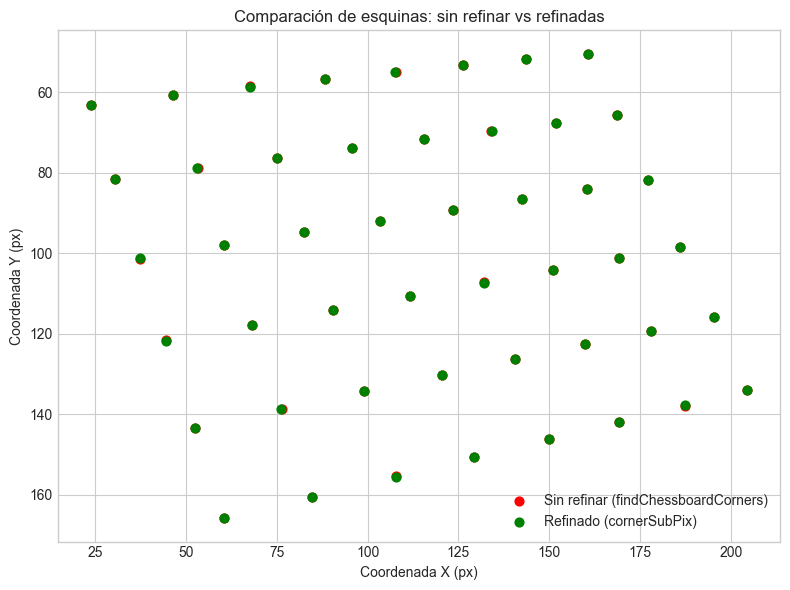

In [72]:
# Mostramos algunos gráficos para ver las diferencias más visualmente
import numpy as np
import matplotlib.pyplot as plt

# Ejemplo con estas imágenes en concreto
corners_raw = corners_right[10][1].reshape(-1, 2)
corners_refined = corners_refined_right[10].reshape(-1, 2)

plt.figure(figsize=(8, 6))
plt.title("Comparación de esquinas: sin refinar vs refinadas")
plt.xlabel("Coordenada X (px)")
plt.ylabel("Coordenada Y (px)")

# Dibujamos los puntos originales (findChessboardCorners)
plt.scatter(corners_raw[:, 0], corners_raw[:, 1], color="red", label="Sin refinar (findChessboardCorners)", s=40)

# Dibujamos los puntos refinados (cornerSubPix)
plt.scatter(corners_refined[:, 0], corners_refined[:, 1], color="green", label="Refinado (cornerSubPix)", s=40)

# Dibujamos líneas que conectan cada par (para ver el desplazamiento)
for raw, refined in zip(corners_raw, corners_refined):
    plt.plot([raw[0], refined[0]], [raw[1], refined[1]], color="gray", linewidth=0.7, alpha=0.6)

plt.gca().invert_yaxis()  
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Error medio: 0.0843 píxeles
Error máximo: 0.2107 píxeles


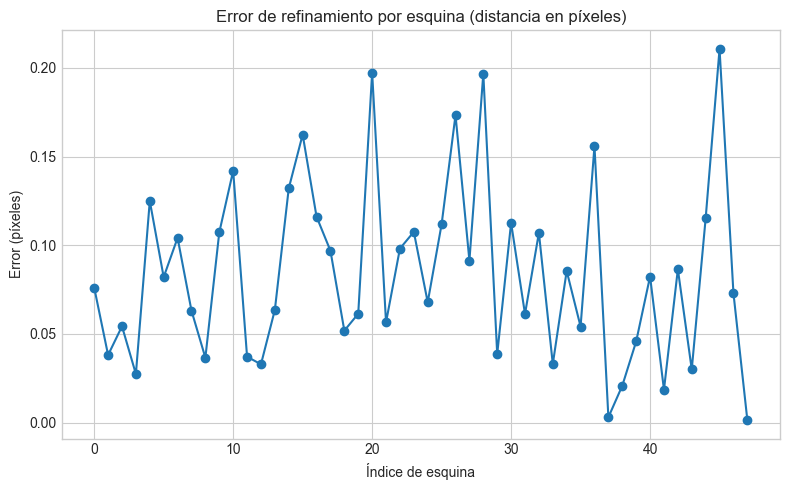

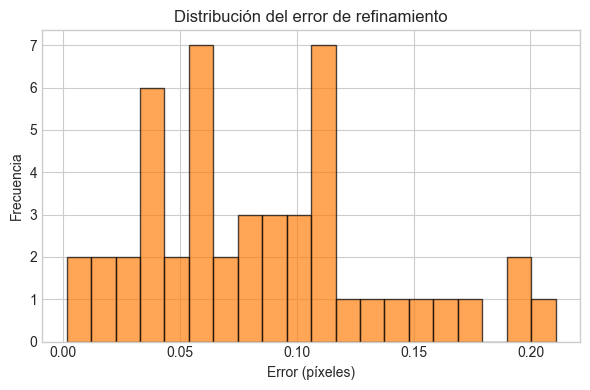

In [70]:
import numpy as np
import matplotlib.pyplot as plt

# Convertimos los arrays a formato (N, 2)
corners_raw = corners_right[10][1].reshape(-1, 2)
corners_refined = corners_refined_right[10].reshape(-1, 2)

# Calculamos el error euclidiano por punto
errors = np.linalg.norm(corners_refined - corners_raw, axis=1)

# Mostramos estadísticas básicas
print(f"Error medio: {errors.mean():.4f} píxeles")
print(f"Error máximo: {errors.max():.4f} píxeles")

# --- Gráfico de errores por punto ---
plt.figure(figsize=(8, 5))
plt.title("Error de refinamiento por esquina (distancia en píxeles)")
plt.plot(errors, marker='o', linestyle='-', color='tab:blue')
plt.xlabel("Índice de esquina")
plt.ylabel("Error (píxeles)")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Gráfico de histograma ---
plt.figure(figsize=(6, 4))
plt.title("Distribución del error de refinamiento")
plt.hist(errors, bins=20, color='tab:orange', edgecolor='black', alpha=0.7)
plt.xlabel("Error (píxeles)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()


### **Pregunta A.3:** Número mínimo de imágenes necesarias para calibrar.

Utilizaremos las imagenes de right para comprobar

In [42]:
imgs_gen_path_right = '../data/right/*.jpg' # patrón que cumplen todos los paths de los archivos de imágenes
imgs_path_right = sorted(glob.glob(imgs_gen_path_right))  # cogemos todos los paths que cumplen ese patrón genérico (usando glob) y los ordenamos (usando sorted)
imgs_right = load_images(imgs_path_right)  # le pasamos a load_images la lista de paths o filenames de las imágenes que queremos cargar

C:\Temp\Win\ipykernel_21776\283608422.py:2: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  return [imageio.imread(filename) for filename in filenames]


In [43]:
imgs_a3 = []
dict_n_rms = {}

for img in imgs_right:

    imgs_a3.append(img)
    
    corners_a3 = [cv2.findChessboardCorners(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), pattern_size) for img in imgs_a3] 

    # Hacemos por seguridad una copia de las esquinas detectadas
    corners_copy_a3 = copy.deepcopy(corners_a3)  

    # Este es el criterio de parada que se usará en cornerSubPix, indica cuándo detener la iteración (por precisión alcanzada o por número máximo de iteraciones)
    criteria_a3 = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01) # En nuestro caso usaremos de condiciones tanto un máximo de 30 iteraciones, como precisión mínima a obtener de 0.01

    # TODO To refine corner detections with cv2.cornerSubPix() you need to input grayscale images. Build a list containing grayscale images.
    imgs_gray_a3 = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in imgs_a3] # pasamos a grises las imágenes

    # Hacemos cornersSubPix para hacer más precisa la localización de esquinas
    corners_refined_a3 = [cv2.cornerSubPix(i, cor[1], pattern_size, (-1, -1), criteria_right) if cor[0] else [] for i, cor in zip(imgs_gray_a3, corners_copy_a3)]

    chessboard_points_a3 = [get_chessboard_points(pattern_size, dx, dy) for _ in corners_refined_a3]

    img_size_a3 = (imgs_gray_a3[0].shape[1], imgs_gray_a3[0].shape[0])  # Extraemos el tamaño de las imágenes: 320 x 240

    # Para que coincidan las dimensiones de los object points y los image points, filtramos entre ellos:
    chessboard_points_valid = []
    valid_corners_a3 = []

    for i, found in enumerate(corners_a3):
        if found[0]:  # solo cogemos los que tienen True en el ret (se contró el patrón con éxito)
            chessboard_points_valid.append(chessboard_points_a3[i])
            valid_corners_a3.append(corners_a3[i][1])

    # Convertimos a array de numpy
    valid_corners_a3 = np.asarray(valid_corners_a3, dtype=np.float32)

    rms_a3, intrinsics_a3, dist_coeffs_a3, rvecs_a3, tvecs_a3 = cv2.calibrateCamera(chessboard_points_valid, valid_corners_a3, img_size_a3, None, None)

    # dict_n_rms[len(imgs_a3)] = rms_a3
    dict_n_rms[len(valid_corners_a3)] = rms_a3

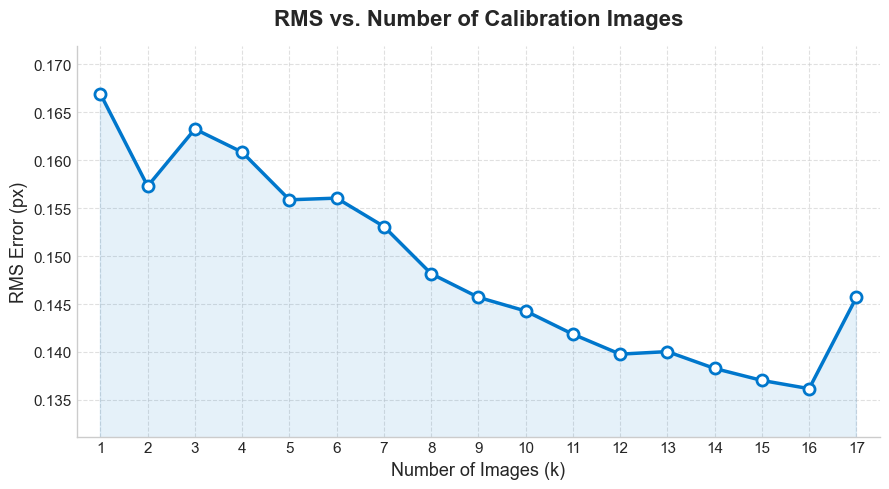

In [44]:
x = sorted(dict_n_rms.keys())
y = [dict_n_rms[k] for k in dict_n_rms]

# Detectar “plateau” automáticamente (mejora < 1%)
diffs = np.abs(np.diff(y))

plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(9, 5))

# Línea principal
ax.plot(x, y, color="#0077cc", linewidth=2.5, marker="o", markersize=8, markerfacecolor="white", markeredgewidth=2)

# Relleno suave bajo la curva
ax.fill_between(x, y, color="#0077cc", alpha=0.1)

# Ejes y labels
ax.set_title("RMS vs. Number of Calibration Images", fontsize=16, weight="bold", pad=15)
ax.set_xlabel("Number of Images (k)", fontsize=13)
ax.set_ylabel("RMS Error (px)", fontsize=13)

# Mostramos todos los ticks del eje X
ax.set_xticks(x)

# Grid y límites
ax.grid(True, which="major", linestyle="--", alpha=0.6)
ax.set_xlim(min(x) - 0.5, max(x) + 0.5)
ax.set_ylim(min(y) - 0.005, max(y) + 0.005)

# Estilo de los ejes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis='both', labelsize=11)

plt.tight_layout()
plt.show()

## **Apartado B: Corrección de distorsión** (ojo de pez)

En este apartado se trabajará en la corrección de la distorsión debido a lentes de ojo de pez. Primero se calibrará una cámara con este tipo de lente, utilizando las imágenes de la carpeta ``fisheye``. Posteriormente se utilizarán estos parámetros de calibración para corregir la distorsión de una de las imágenes de calibración.

Los pasos que deberá seguir para calibrar una cámara con distorsión de ojo de pez son:

1. Reutilice el método ``load_images()`` para cargar las imágenes de la carpeta ``fisheye``.
2. Detecte las equinas procesando las imágenes con los métodos ``cv2.findChessboardCorners()`` y ``cv2.cornerSubPix()``.
3. Reutilice la función ``get_chessboard_points()`` para obtener las coordenadas del tablero.
4. Defina los argumentos para la función de calibración.
5. Calibre con ``cv2.fisheye.calibrate()``

### **Tarea B.1:** Reutilice el método ``load_images()`` para cargar las imágenes de la carpeta ``fisheye``

In [45]:
# TODO Build a list containing the paths of all images from the fisheye camera and load images

fisheye_imgs_path = '../data/fisheye/*.jpg' # patrón que cumplen todos los paths de los archivos de imágenes de fisheye
imgs_fisheye_path = sorted(glob.glob(fisheye_imgs_path))  # cogemos todos los paths que cumplen ese patrón genérico (usando glob) y los ordenamos (usando sorted)
fisheye_imgs = load_images(imgs_fisheye_path)  # le pasamos a load_images la lista de paths o filenames de las imágenes que queremos cargar

imgs_fisheye_path

C:\Temp\Win\ipykernel_21776\283608422.py:2: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  return [imageio.imread(filename) for filename in filenames]


['../data/fisheye\\VMRImage0.jpg',
 '../data/fisheye\\VMRImage1.jpg',
 '../data/fisheye\\VMRImage2.jpg',
 '../data/fisheye\\VMRImage3.jpg',
 '../data/fisheye\\VMRImage4.jpg',
 '../data/fisheye\\VMRImage5.jpg',
 '../data/fisheye\\VMRImage6.jpg',
 '../data/fisheye\\VMRImage7.jpg',
 '../data/fisheye\\VMRImage8.jpg',
 '../data/fisheye\\VMRImage9.jpg']

### **Tarea B.2:** Detecte las equinas procesando las imágenes con los métodos ``cv2.findChessboardCorners()`` y ``cv2.cornerSubPix()``.

In [46]:
# Contamos a mano cuantas esquinas de filas y columnas hay en el tablero de chess
fisheye_size_pattern = (7,6)  # Sigue el formato fila, columna. Indica cuántas esquinas interiores hay que detectar en cada fila y cada columna 

imgs_corners = []  # inicializamos la lista en la que vamos a ir guardando los corners detectados con cornerSubPix y findChessboardCorners

# Parameters for cv2.cornerSubPix()
subpix_criteria = (cv2.TERM_CRITERIA_EPS+cv2.TERM_CRITERIA_MAX_ITER, 30, 0.1)

#TODO Complete the required parts of the loop
for img in fisheye_imgs:
    
    # TODO parse arguments to cv2.findChessboardCorners()
    corners = cv2.findChessboardCorners(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), fisheye_size_pattern)
    
    # TODO convert image to grayscale to use cv2.cornerSubPix()
    gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    if corners[0]:  # solo cogemos los resultados donde la búsqueda del patrón haya sido exitosa
        refined_corners = cv2.cornerSubPix(gray_img, corners[1], (3,3), (-1,-1), subpix_criteria)

        # TODO append only those refined_corners with proper detections
        imgs_corners.append(refined_corners)

In [47]:
# Hacemos una copia de las imágenes por seguridad, ya que ahora las vamos a sobreescribir
fisheye_imgs_copy = copy.deepcopy(fisheye_imgs)

# Mostramos qué tal han quedado las esquinas encontradas en los tableros
for i in range(len(imgs_corners)):
    cv2.drawChessboardCorners(fisheye_imgs_copy[i], fisheye_size_pattern, imgs_corners[i], True)
    cv2.imshow(f"Img fisheye {i}",fisheye_imgs_copy[i])
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [48]:
for i in range(len(imgs_corners)):
    write_image("imagenes_esquinas_fisheye", f"patron_{i}.jpg", fisheye_imgs_copy[i])

### **Tarea B.3:** Reutilice la función ``get_chessboard_points()`` para obtener las coordenadas del tablero

In [49]:
# TODO Define the chessboard dimensions and the lenght of the squares (in [mm])
chessboard_dims = (7, 6)  # número de esquinas interiores en cada fila y columna
dx, dy = 30, 30  # longitud de los cuadrados de 30mm

# TODO You need the points for every image, not just one (consider a list comprehension)
fisheye_chessboard_points = [get_chessboard_points(chessboard_dims, dx, dy).reshape(-1,1,3) for _ in imgs_corners]  # solo creamos el tablero para las detecciones que han sido exitosas


In [50]:
# Vemos que las dimensiones de la cuadrícula de cada imagen son (42, 1, 3) ya que hay 7x6 = 42 esquinas, y cada esquina está dada por unas coordenadas x,y,z (con la z siempre en cero)
print(fisheye_chessboard_points[0].shape , "\n")

# Además, comprobamos que la forma de la cuadrícula generada es la correcta
print(fisheye_chessboard_points[0])

(42, 1, 3) 

[[[  0.   0.   0.]]

 [[ 30.   0.   0.]]

 [[ 60.   0.   0.]]

 [[ 90.   0.   0.]]

 [[120.   0.   0.]]

 [[150.   0.   0.]]

 [[180.   0.   0.]]

 [[  0.  30.   0.]]

 [[ 30.  30.   0.]]

 [[ 60.  30.   0.]]

 [[ 90.  30.   0.]]

 [[120.  30.   0.]]

 [[150.  30.   0.]]

 [[180.  30.   0.]]

 [[  0.  60.   0.]]

 [[ 30.  60.   0.]]

 [[ 60.  60.   0.]]

 [[ 90.  60.   0.]]

 [[120.  60.   0.]]

 [[150.  60.   0.]]

 [[180.  60.   0.]]

 [[  0.  90.   0.]]

 [[ 30.  90.   0.]]

 [[ 60.  90.   0.]]

 [[ 90.  90.   0.]]

 [[120.  90.   0.]]

 [[150.  90.   0.]]

 [[180.  90.   0.]]

 [[  0. 120.   0.]]

 [[ 30. 120.   0.]]

 [[ 60. 120.   0.]]

 [[ 90. 120.   0.]]

 [[120. 120.   0.]]

 [[150. 120.   0.]]

 [[180. 120.   0.]]

 [[  0. 150.   0.]]

 [[ 30. 150.   0.]]

 [[ 60. 150.   0.]]

 [[ 90. 150.   0.]]

 [[120. 150.   0.]]

 [[150. 150.   0.]]

 [[180. 150.   0.]]]


### **Tarea B.4:** Defina los argumentos para la calibración

In [51]:
# Parameters for cv2.fisheye.calibrate()

# Preparamos una serie de variables necesarias antes de llamar a cv2.fisheye.calibrate(), la función de OpenCV que realiza la calibración de una cámara con lente ojo de pez (fisheye camera model)
calibration_flags = cv2.fisheye.CALIB_RECOMPUTE_EXTRINSIC+cv2.fisheye.CALIB_FIX_SKEW  # Estas constantes controlan cómo se comporta el algoritmo de calibración, en este caso las sumamos
intrinsics = np.zeros((3, 3))  # Se inicializa como una matriz 3×3 de ceros que será rellenada por cv2.fisheye.calibrate() con los parámetros intrínsecos de la cámara
distortion = np.zeros((4, 1))  # Se inicializan como un vector columna 4×1 de ceros. El modelo fisheye de OpenCV utiliza cuatro parámetros de distorsión radial
rotations = [np.zeros((1, 1, 3), dtype=np.float64) for _ in imgs_corners]  # Se crea una lista donde cada elemento es un array 1×1×3 inicializado a cero (uno por cada imagen utilizada en la calibración)
traslations = [np.zeros((1, 1, 3), dtype=np.float64) for _ in imgs_corners]  # Igual que lo anterior, pero describe la posición del patrón respecto a la cámara


### **Tarea B.5:** Calibración

In [52]:
# Esta línea ejecuta el proceso de calibración de cámara ojo de pez (fisheye), rellenando los parámetros que le habíamos definido antes
rms, _, _, _, _ = \
cv2.fisheye.calibrate(fisheye_chessboard_points,   # Lista de arrays con las coordenadas reales de las esquinas del tablero, expresadas en el sistema del mundo
                      imgs_corners, gray_img.shape[::-1],  # Lista de arrays con las coordenadas en píxeles de las esquinas detectadas en cada imagen, refinadas con cv2.cornerSubPix()
                      intrinsics, distortion, rotations, traslations, calibration_flags, # Los parámetros que queremos calibrar usando el algoritmo
                      subpix_criteria)  # Condición que define cuándo detener la optimización iterativa (por número máximo de iteraciones o por error mínimo alcanzado)

# La función estima los parámetros intrínsecos y de distorsión de la cámara de lente de pez, a partir de un conjunto de imágenes de un patrón conocido en nuestro caso un tablero de ajedrez

In [53]:
# Show intrinsic matrix and distortion coefficients values
print("Intrinsic matrix:\n", intrinsics)
print("\nDistortion coefficients:\n", distortion)

Intrinsic matrix:
 [[188.86914026   0.         503.92900347]
 [  0.         185.32638678 373.58044468]
 [  0.           0.           1.        ]]

Distortion coefficients:
 [[ 0.07734388]
 [ 0.01482361]
 [ 0.02351869]
 [-0.02757565]]


### **Pregunta B.1:** Corrija la distorsión de las 2 primeras imágenes de la carpeta ``fisheye``

In [54]:
# La función de fisheye.initUndistortRectifyMap requiere del parámetro dim, que son las dimensiones de las imágenes que se quieren corregir
for i in range(len(fisheye_imgs)):
    print(fisheye_imgs[i].shape)


(768, 1024, 3)
(768, 1024, 3)
(768, 1024, 3)
(768, 1024, 3)
(768, 1024, 3)
(768, 1024, 3)
(768, 1024, 3)
(768, 1024, 3)
(768, 1024, 3)
(768, 1024, 3)


In [55]:
# TODO Search in the documentation to define 'dim'
dim = (fisheye_imgs[0].shape[0], fisheye_imgs[0].shape[1])  # pasamos las dimensiones de las imágenes que queremos corregir, que serán de (768, 1024)

# La función de fisheye.initUndistortRectifyMap no genera imágenes directamente, sino que calcula dos mapas de remapeo (map1 y map2) que contienen, para cada píxel de la imagen 
# rectificada (sin distorsión), la posición de dónde debe tomar su valor en la imagen original (distorsionada). Luego, esos mapas se usan en la función de cv2.remap
map1, map2 = cv2.fisheye.initUndistortRectifyMap(intrinsics, distortion, np.eye(3), intrinsics, dim, cv2.CV_16SC2)

In [56]:
# Exploramos un poco map1 y map2
print(len(map1))  # Indica de qué píxel original leer cada píxel corregido
print(len(map2))  # Mejora la precisión del remapeo subpíxel

1024
1024


In [57]:
print(map1[0].shape)
print(map2[0].shape)

# Son matrices NumPy que almacenan las coordenadas de mapeo necesarias para transformar la imagen distorsionada en una imagen rectificada.

(768, 2)
(768,)


In [58]:
# TODO Homework: correct distortion using cv2.remap()

# Hacemos una copia de seguridad por si acaso
undistorted_fisheye_imgs_copy = copy.deepcopy(fisheye_imgs) 

# Obtenemos las imágenes ya sin distorsión gracias a la función de remapm, que aplicamos para cada una de las imágenes iniciales
undistorted_fisheye_imgs = [cv2.remap(img, map1, map2, interpolation=cv2.INTER_LINEAR) for img in undistorted_fisheye_imgs_copy]
# cv2.remap() crea una nueva imagen tomando los valores de la imagen original y aplicandole el remapeo necesario mediante map1 y map2

In [59]:
for i in range(len(undistorted_fisheye_imgs_copy)):

    # Mostramos ambas imágenes para comparar (las distorsionadas y las corregidas)
    cv2.imshow(f"Original (Distorsionada) {i}", fisheye_imgs[i])
    cv2.imshow(f"Rectificada (Sin distorsion) {i}", undistorted_fisheye_imgs[i])
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [60]:
# Mostramos las imágenes sin distorsión de las 2 primeras imágenes de la carpeta de fisheye, como pide el enunciado

n = 0

cv2.imshow(f"Rectificada (Sin distorsion) {n}", undistorted_fisheye_imgs[n])
cv2.waitKey(0)
cv2.destroyAllWindows()

cv2.imshow(f"Rectificada (Sin distorsion) {n+1}", undistorted_fisheye_imgs[n+1])
cv2.waitKey(0)
cv2.destroyAllWindows()

In [61]:
for i in range(n+2):
    write_image("no_distorision_fisheye", f"no_distorsion_{i}.jpg", undistorted_fisheye_imgs[i])